In [1]:
pip install pydub

In [52]:
pip install pyphonetics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 235.5/235.5 kB 8.7 MB/s eta 0:00:00


In [93]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import random
import shutil
import ast
import librosa
import librosa.display
from sklearn.decomposition import PCA
from pydub import AudioSegment
import numpy as np
import seaborn as sns


In [4]:
validated_df = pd.read_csv(r'/content/sample_data/Metadata/validated.tsv', sep='\t')
validated_sentences_df = pd.read_csv(r'/content/sample_data/Metadata/validated_sentences.tsv', sep='\t')
invalidated_df = pd.read_csv(r'/content/sample_data/Metadata/invalidated.tsv', sep='\t')
invalidated_sentences_df = pd.read_csv(r'/content/sample_data/Metadata/unvalidated_sentences.tsv', sep='\t')
test_df = pd.read_csv(r'/content/sample_data/Metadata/test.tsv', sep='\t')
train_df = pd.read_csv(r'/content/sample_data/Metadata/train.tsv', sep='\t')
clip_duration_df = pd.read_csv(r'/content/sample_data/Metadata/clip_durations.tsv', sep='\t')
reported_df = pd.read_csv(r'/content/sample_data/Metadata/reported.tsv', sep='\t')

In [5]:
print(f"Total validated clips: {validated_df.shape[0]}")
print(f"Total unvalidated clips: {invalidated_df.shape[0]}")

Total validated clips: 52144
Total unvalidated clips: 6839


Data pre-processing for the textual data present before doing EDA

In [6]:
print(validated_df.isnull().sum())
print(validated_df.shape)

client_id              0
path                   0
sentence_id            0
sentence               0
sentence_domain    52144
up_votes               0
down_votes             0
age                 4942
gender              4910
accents            43279
variant            52144
locale                 0
segment            52144
dtype: int64
(52144, 13)


In [7]:
validated_df_clean=validated_df.drop(columns=['variant','segment','sentence_domain'])
print(validated_df_clean.isnull().sum())

client_id          0
path               0
sentence_id        0
sentence           0
up_votes           0
down_votes         0
age             4942
gender          4910
accents        43279
locale             0
dtype: int64


In [8]:
print(invalidated_df.isnull().sum())
print(invalidated_df.shape)

client_id             0
path                  0
sentence_id           0
sentence              0
sentence_domain    6839
up_votes              0
down_votes            0
age                1022
gender             1021
accents            5025
variant            6839
locale                0
segment            6839
dtype: int64
(6839, 13)


In [9]:
invalidated_df_clean=invalidated_df.drop(columns=['sentence_domain','segment','variant'])
print(invalidated_df_clean.isnull().sum())

client_id         0
path              0
sentence_id       0
sentence          0
up_votes          0
down_votes        0
age            1022
gender         1021
accents        5025
locale            0
dtype: int64


In [10]:
print(validated_sentences_df.isnull().sum())
print(validated_sentences_df.shape)
validated_sentences_df_clean=validated_sentences_df.drop(columns=['sentence_domain'])
print(validated_sentences_df_clean.isnull().sum())

sentence_id            0
sentence               0
sentence_domain    18211
source                 0
is_used                0
clips_count            0
dtype: int64
(18211, 6)
sentence_id    0
sentence       0
source         0
is_used        0
clips_count    0
dtype: int64


In [11]:
print(invalidated_sentences_df.isnull().sum())
print(invalidated_sentences_df.shape)
invalidated_sentences_df_clean=invalidated_sentences_df.drop(columns=['sentence_domain'])
print(invalidated_sentences_df_clean.isnull().sum())

sentence_id            0
sentence               0
sentence_domain    50394
source                 6
dtype: int64
(50398, 4)
sentence_id    0
sentence       0
source         6
dtype: int64


In [12]:
print(clip_duration_df.isnull().sum())
print(reported_df.isnull().sum())

clip            0
duration[ms]    0
dtype: int64
sentence_id    0
sentence       0
locale         0
reason         0
dtype: int64


EDA

In [13]:
print("Validated DataFrame Descriptive Statistics:")
print(validated_df_clean.describe())

Validated DataFrame Descriptive Statistics:
          up_votes    down_votes
count  52144.00000  52144.000000
mean       3.68656      0.260394
std        3.03843      0.771776
min        2.00000      0.000000
25%        2.00000      0.000000
50%        3.00000      0.000000
75%        4.00000      0.000000
max       65.00000     18.000000


In [14]:
print("\nValidated Sentences DataFrame Descriptive Statistics:")
print(validated_sentences_df_clean.describe())



Validated Sentences DataFrame Descriptive Statistics:
       is_used   clips_count
count  18211.0  18211.000000
mean       1.0     10.859920
std        0.0      2.164788
min        1.0      0.000000
25%        1.0     10.000000
50%        1.0     12.000000
75%        1.0     12.000000
max        1.0     16.000000


In [15]:
print("\nInvalidated DataFrame Descriptive Statistics:")
print(invalidated_df_clean.describe())


Invalidated DataFrame Descriptive Statistics:
          up_votes   down_votes
count  6839.000000  6839.000000
mean      0.864308     3.207633
std       1.509746     2.433231
min       0.000000     2.000000
25%       0.000000     2.000000
50%       0.000000     2.000000
75%       1.000000     4.000000
max      21.000000    36.000000


In [16]:
print("\nInvalidated Sentences DataFrame Descriptive Statistics:")
print(invalidated_sentences_df_clean.describe())


Invalidated Sentences DataFrame Descriptive Statistics:
                                              sentence_id  \
count                                               50398   
unique                                              50398   
top     0016f53c42f5ee477733579eb7b10492794717f76c242a...   
freq                                                    1   

                            sentence                                    source  
count                          50398                                     50392  
unique                         50371                                       340  
top     اس بارے ہم کر کچھ نہیں سکتے۔  https://github.com/naeem9/urdu-sentences  
freq                               2                                     15978  


In [17]:
print("\nClip Duration DataFrame Descriptive Statistics:")
print(clip_duration_df.describe())


Clip Duration DataFrame Descriptive Statistics:
        duration[ms]
count  196558.000000
mean     4246.105658
std      3371.821598
min       216.000000
25%      2916.000000
50%      3888.000000
75%      5040.000000
max    278460.000000


In [18]:
print(validated_df_clean.isnull().sum())
validated_df_clean['gender'] = validated_df_clean['gender'].fillna('Unknown')
print(validated_df_clean.isnull().sum())


client_id          0
path               0
sentence_id        0
sentence           0
up_votes           0
down_votes         0
age             4942
gender          4910
accents        43279
locale             0
dtype: int64
client_id          0
path               0
sentence_id        0
sentence           0
up_votes           0
down_votes         0
age             4942
gender             0
accents        43279
locale             0
dtype: int64


Now checking validated_df

In [19]:
for col in ['client_id', 'path', 'sentence_id', 'sentence', 'age', 'gender', 'accents', 'locale']:
    print(f'Column: {col}')
    print(validated_df_clean[col].value_counts())
    print()

#path contain audio files so all are unique
#client_id has 308 unique identitfiers
#sentence has 13534 unique ones
# gender shows
# male_masculine     33947
#female_feminine    13287
#age shows
#twenties    45943
#fourties      815
#thirties      244
#teens         199
#sixties         1
#accents multiple unique ones
#locale is for each audio so all rows are unique

Column: client_id
client_id
b6a2de1b8b5e69fda59c63aaac8102ee46363d17f839436421568481abcecd8e96987ed9091c503c950eb3f0093944a7a0b534ef90f490fc2266509a37864f8e    1831
a0f8a9ee1690fefc5c61e0d739761cf69491a9632015dadf1ceb80360c2017ac6cc4befad1e27f0cfc90432350d7f131bea0db873d3d0c7b7d6ccf3fbcfd943f    1741
af922fa0f01deedfa757fd8eebab0e68e9aabe11574bc2c449c45b6a3a10638f39153c85278cc186cdf9b58211322cf1479bc8f6dcc0b35d9873db0cf27bc52f    1506
9a2de47f11bea8ec48b7bf5b03f2ca13e81cdba7db0eb85c1378f7cc13ece0a689209a22bda45ed7b4c3bf8a6cf44738228ef7cd2d547b59e0201aa4e4f204e5    1396
0f06cd0a9583eead42cf1635da1f16265155b8cdd013c8a57c34a30cd996f466393f40b270f6880b529de6da060905ae36685fa14ad0e73981cb06c51a7bfc47    1332
                                                                                                                                    ... 
e0b1bcf588e7390a784ef15eebb4d44b52b9f9d7b09030babb6c7b79cc87d42983dceb628b93d5a9cec23563c56b1dc155d0109c1365a2de72c9256c88d4e945       1
e0d51c00b0faf

In [20]:
#How many recordings are done by each client_id
client_id_counts = validated_df_clean['client_id'].value_counts()
print(client_id_counts)


client_id
b6a2de1b8b5e69fda59c63aaac8102ee46363d17f839436421568481abcecd8e96987ed9091c503c950eb3f0093944a7a0b534ef90f490fc2266509a37864f8e    1831
a0f8a9ee1690fefc5c61e0d739761cf69491a9632015dadf1ceb80360c2017ac6cc4befad1e27f0cfc90432350d7f131bea0db873d3d0c7b7d6ccf3fbcfd943f    1741
af922fa0f01deedfa757fd8eebab0e68e9aabe11574bc2c449c45b6a3a10638f39153c85278cc186cdf9b58211322cf1479bc8f6dcc0b35d9873db0cf27bc52f    1506
9a2de47f11bea8ec48b7bf5b03f2ca13e81cdba7db0eb85c1378f7cc13ece0a689209a22bda45ed7b4c3bf8a6cf44738228ef7cd2d547b59e0201aa4e4f204e5    1396
0f06cd0a9583eead42cf1635da1f16265155b8cdd013c8a57c34a30cd996f466393f40b270f6880b529de6da060905ae36685fa14ad0e73981cb06c51a7bfc47    1332
                                                                                                                                    ... 
e0b1bcf588e7390a784ef15eebb4d44b52b9f9d7b09030babb6c7b79cc87d42983dceb628b93d5a9cec23563c56b1dc155d0109c1365a2de72c9256c88d4e945       1
e0d51c00b0faf471cee34b6bb8909ed

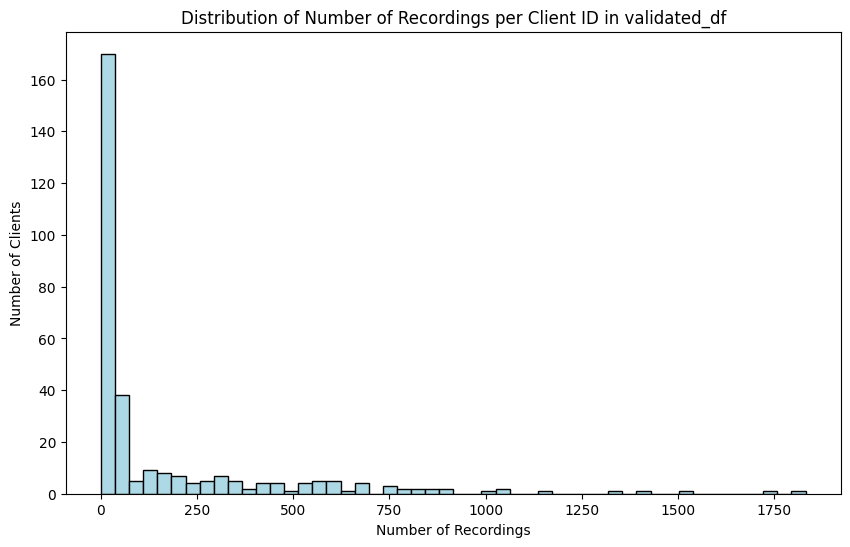

In [21]:
#Create a histogram of the number of recordings per client_id
plt.figure(figsize=(10, 6))
plt.hist(client_id_counts, bins=50, color='lightblue', edgecolor='black')
plt.xlabel('Number of Recordings')
plt.ylabel('Number of Clients')
plt.title('Distribution of Number of Recordings per Client ID in validated_df')
plt.show()


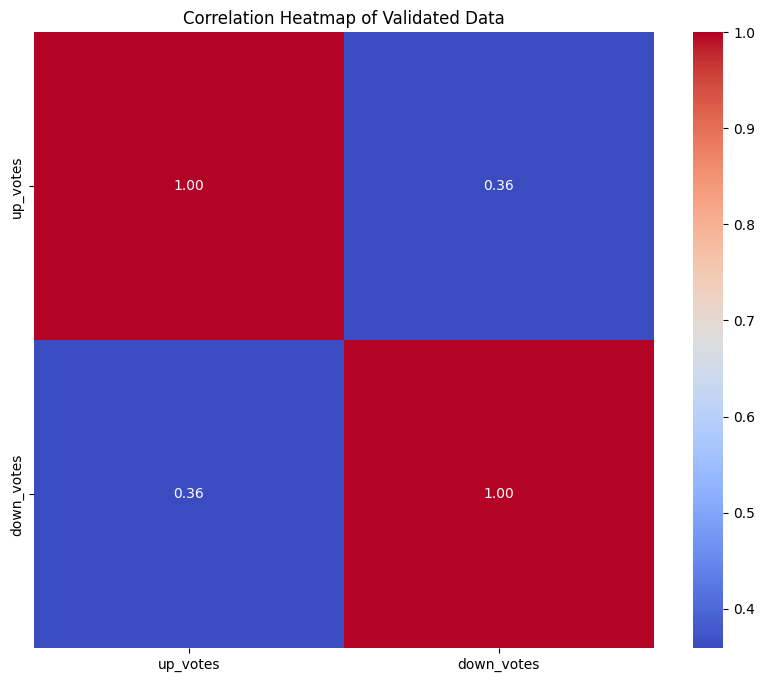

In [22]:
numeric_df = validated_df_clean.select_dtypes(include=['float64', 'int64'])
corr_matrix = numeric_df.corr()
#Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Validated Data')
plt.show()

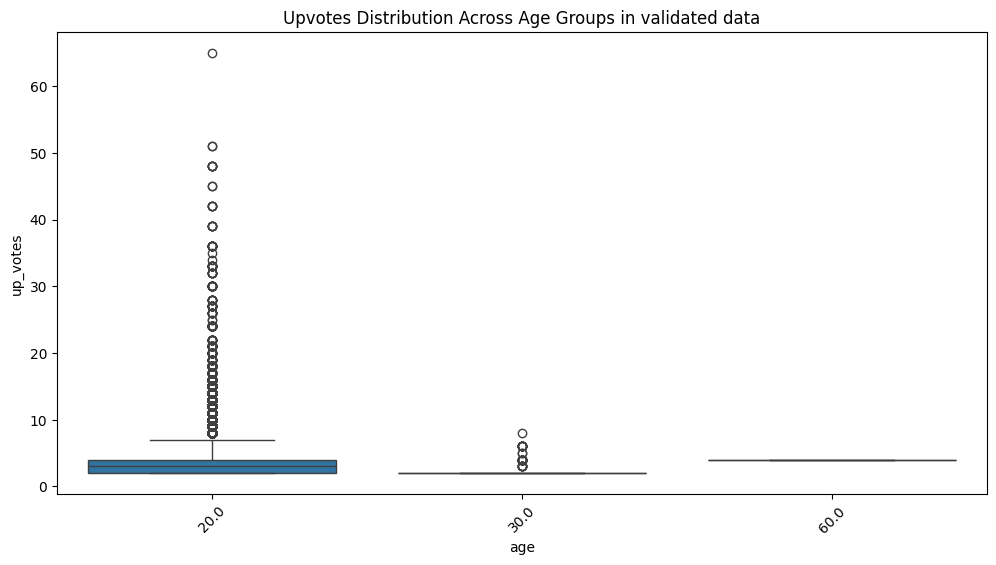

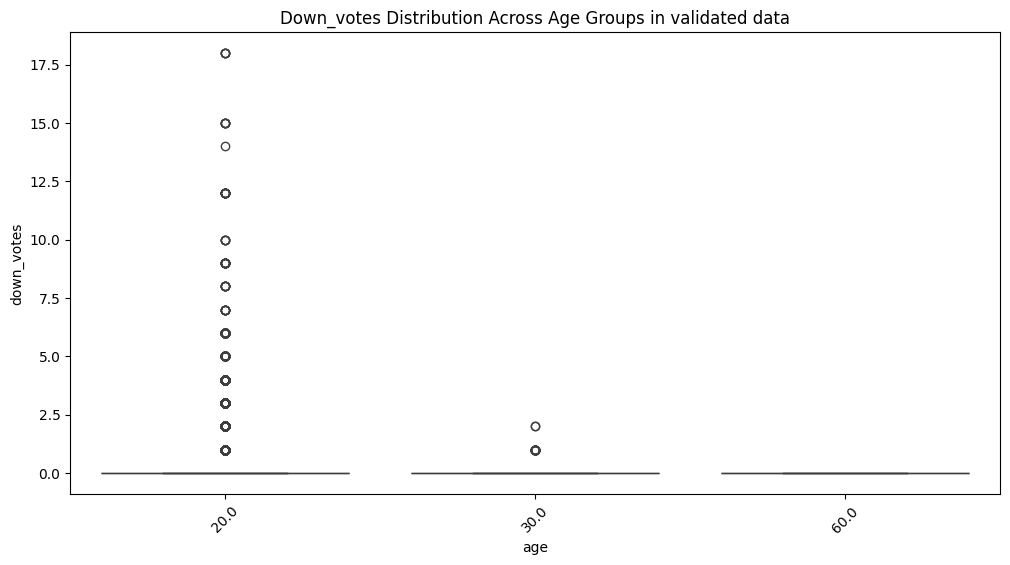

In [97]:
#Relation between Age group and down_votes and up_votes in validated data
plt.figure(figsize=(12, 6))
sns.boxplot(x='age', y='up_votes', data=validated_df_clean)
plt.title('Upvotes Distribution Across Age Groups in validated data')
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(12, 6))
sns.boxplot(x='age', y='down_votes', data=validated_df_clean)
plt.title('Down_votes Distribution Across Age Groups in validated data')
plt.xticks(rotation=45)
plt.show()


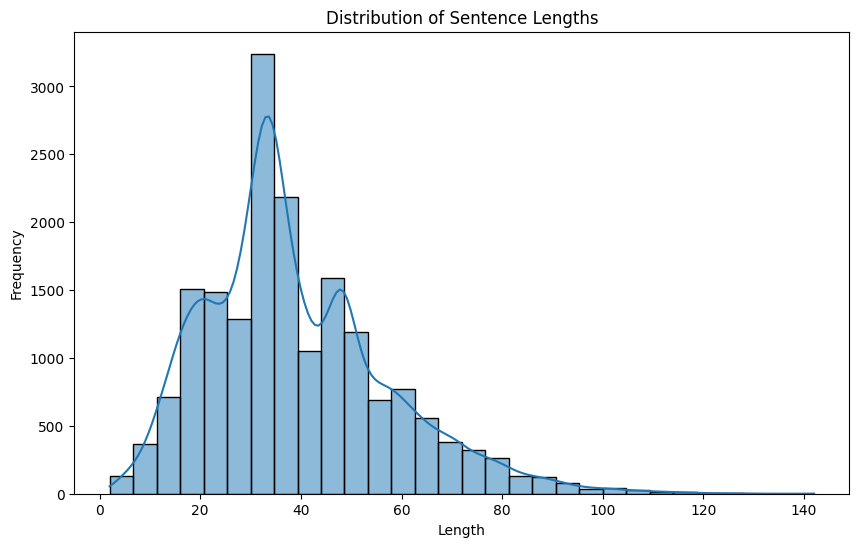

In [24]:
#Validated data sentence vs frequency
validated_sentences_df_clean['sentence_length'] = validated_sentences_df_clean['sentence'].apply(len)
plt.figure(figsize=(10, 6))
sns.histplot(validated_sentences_df_clean['sentence_length'], bins=30, kde=True)
plt.title('Distribution of Sentence Lengths')
plt.xlabel('Length')
plt.ylabel('Frequency')
plt.show()


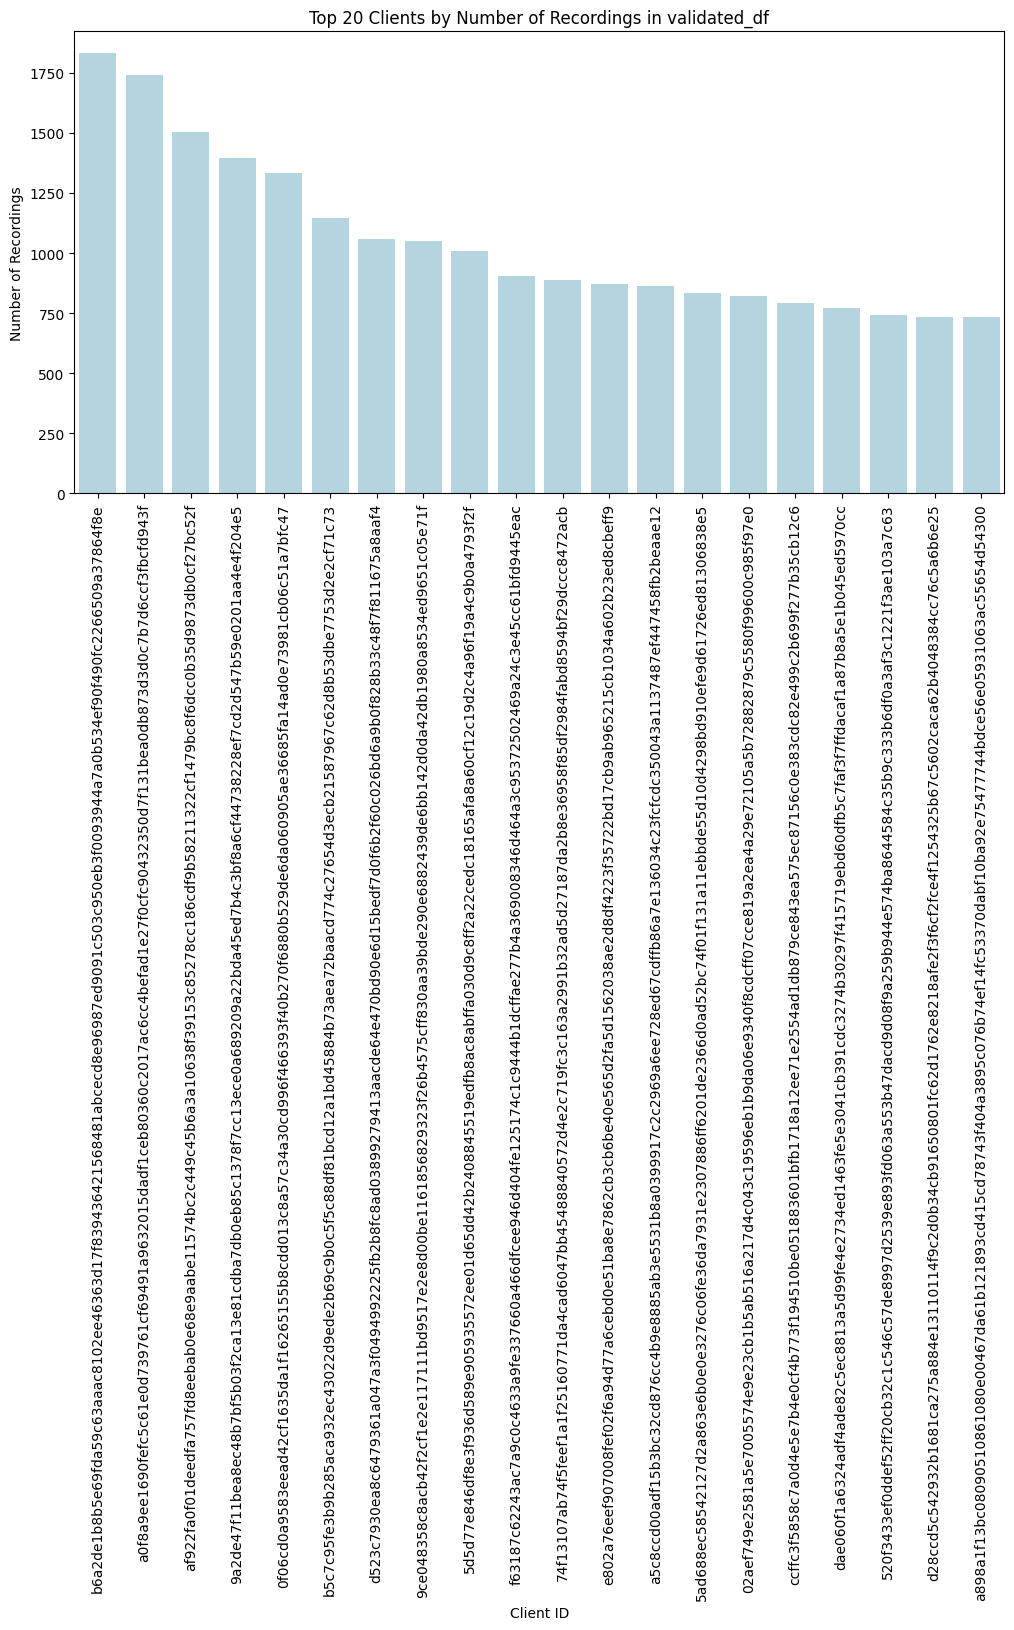

In [25]:
#Since the data is too large to visualise i get the top 20 clients by number of recordings
top_clients = client_id_counts.head(20)
top_clients_df = top_clients.reset_index()
top_clients_df.columns = ['client_id', 'recordings']
#Create the bar plot
plt.figure(figsize=(12, 6))
sns.barplot(x='client_id', y='recordings', data=top_clients_df, color='lightblue')
plt.xticks(rotation=90)
plt.xlabel('Client ID')
plt.ylabel('Number of Recordings')
plt.title('Top 20 Clients by Number of Recordings in validated_df')
plt.show()


Now checking invalidated_df

In [26]:
for col in ['client_id', 'path', 'sentence_id', 'sentence', 'age', 'gender', 'accents', 'locale']:
    print(f'Column: {col}')
    print(invalidated_df_clean[col].value_counts())
    print()

#path contains 6839 audio files so all are unique
#client_id has 239 unique identitfiers
#sentence_id has 5226 unique ones
# gender shows
# male_masculine     4725
#female_feminine    1093
#age shows
#twenties    5701
#fourties      54
#thirties      11
#teens         50
#fifties         1
#accents multiple unique ones
#locale is for each audio so all rows are unique


Column: client_id
client_id
34079be9f9ef68de28d960aa76f53aae052feeb0724efee75540ac378ab61a0b83faf8de6fd27d0d74c8034c3c371eb64714e03c947a991ebc69578803e3d6da    472
a866e6e3e272389978bca1c0b9499268d90574792370df4222466ff7a1d45c8b17445d42fc52c2a84625f439222b78362f60891672ada34185498942caf62fd7    418
dfbbb28a0ad90da59fd1d13620a0dce9fd3cdc8cf5206828e4c9b72a6009b56700760fce7dea08076e2b33611f44632aac2d451c2a85e5dd6a2df36779e51c4a    375
3606b5a1ca688436612810d65531bd6166225193c405c95e700fdc096c80f31cd4aa103a71a5cd10d2ab3f03fb63efbfa915d5294bfd7e247baf6d93b055139d    368
5e53d8511511b9345bf1e8840cbb8e6431341091f66f45af8924472a68a795c697eb03bccf65fc4d79c1d030df2e25e8d04ce635fa8563c0c6935aebebed9175    289
                                                                                                                                   ... 
01db27d5c60def298fe329d9b9853f92f0c163ce902237fa4f74a383cfc816239d39fa09450f5157f2e1f87ef40b19e5a168516be35ed571c6ff07ff79066497      1
6ffe21d438a93b0a7275

In [27]:
#How many recordings are done by each client_id
client_id_counts = invalidated_df_clean['client_id'].value_counts()
print(client_id_counts)


client_id
34079be9f9ef68de28d960aa76f53aae052feeb0724efee75540ac378ab61a0b83faf8de6fd27d0d74c8034c3c371eb64714e03c947a991ebc69578803e3d6da    472
a866e6e3e272389978bca1c0b9499268d90574792370df4222466ff7a1d45c8b17445d42fc52c2a84625f439222b78362f60891672ada34185498942caf62fd7    418
dfbbb28a0ad90da59fd1d13620a0dce9fd3cdc8cf5206828e4c9b72a6009b56700760fce7dea08076e2b33611f44632aac2d451c2a85e5dd6a2df36779e51c4a    375
3606b5a1ca688436612810d65531bd6166225193c405c95e700fdc096c80f31cd4aa103a71a5cd10d2ab3f03fb63efbfa915d5294bfd7e247baf6d93b055139d    368
5e53d8511511b9345bf1e8840cbb8e6431341091f66f45af8924472a68a795c697eb03bccf65fc4d79c1d030df2e25e8d04ce635fa8563c0c6935aebebed9175    289
                                                                                                                                   ... 
01db27d5c60def298fe329d9b9853f92f0c163ce902237fa4f74a383cfc816239d39fa09450f5157f2e1f87ef40b19e5a168516be35ed571c6ff07ff79066497      1
6ffe21d438a93b0a727528102a0f5e5cd8dbae

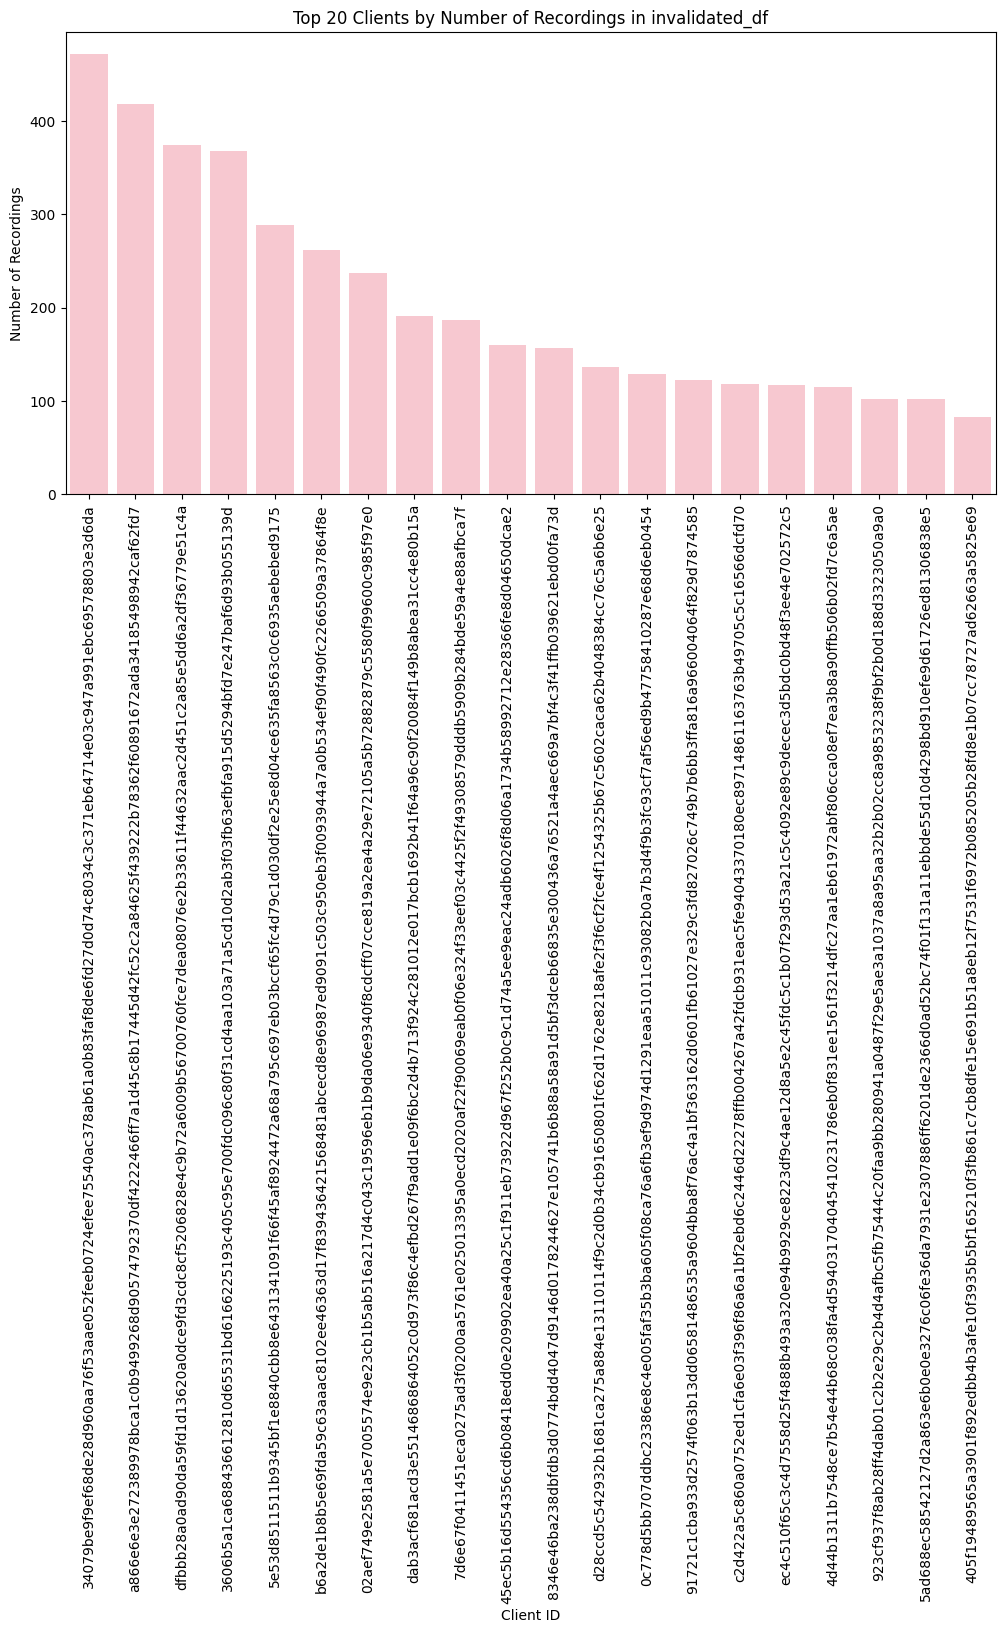

In [28]:
#Same above approach using top 20 clients
top_clients = client_id_counts.head(20)
top_clients_df = top_clients.reset_index()
top_clients_df.columns = ['client_id', 'recordings']

#Create the bar plot
plt.figure(figsize=(12, 6))
sns.barplot(x='client_id', y='recordings', data=top_clients_df, color='pink')
plt.xticks(rotation=90)
plt.xlabel('Client ID')
plt.ylabel('Number of Recordings')
plt.title('Top 20 Clients by Number of Recordings in invalidated_df')
plt.show()


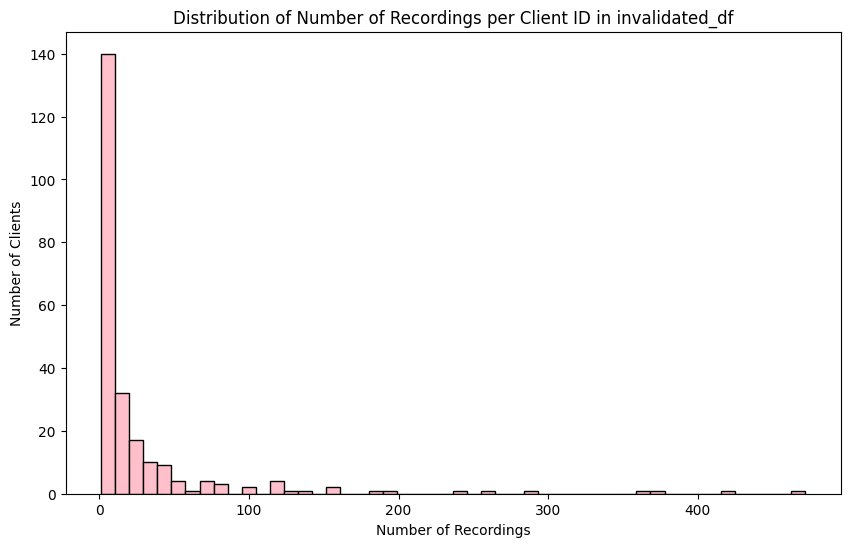

In [29]:
#Create a histogram of the number of recordings per client_id
plt.figure(figsize=(10, 6))
plt.hist(client_id_counts, bins=50, color='pink', edgecolor='black')
plt.xlabel('Number of Recordings')
plt.ylabel('Number of Clients')
plt.title('Distribution of Number of Recordings per Client ID in invalidated_df')
plt.show()

Working on both valid and invalidated_df

In [30]:
#Converting categorical age data into numerical data for further visualisations
age_mapping = {
    'twenties': 20,
    'thirties': 30,
    'forties': 40,
    'fifties': 50,
    'sixties': 60,
}
validated_df_clean['age'] = validated_df_clean['age'].map(age_mapping)
invalidated_df_clean['age'] = invalidated_df_clean['age'].map(age_mapping)

print(validated_df_clean['age'].head())
print(invalidated_df_clean['age'].head())



0    20.0
1     NaN
2    20.0
3    60.0
4    20.0
Name: age, dtype: float64
0    20.0
1    20.0
2    20.0
3    20.0
4    20.0
Name: age, dtype: float64


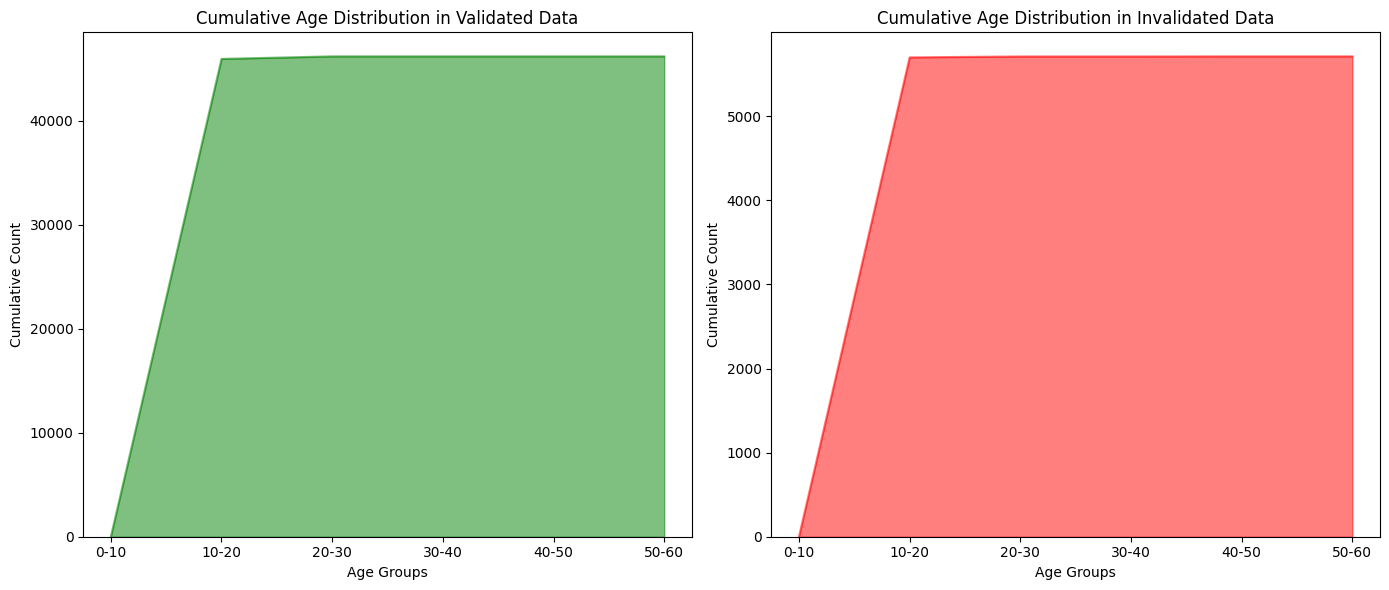

In [32]:
bins = range(0, 70, 10)
labels = [f'{i}-{i+10}' for i in bins[:-1]]

#Age distribution for validated data
validated_age_groups = pd.cut(validated_df_clean['age'].dropna(), bins=bins, labels=labels).value_counts().sort_index()

#Age distribution for invalidated data
invalidated_age_groups = pd.cut(invalidated_df_clean['age'].dropna(), bins=bins, labels=labels).value_counts().sort_index()

#Cumulative counts
validated_age_cumulative = validated_age_groups.sort_index().cumsum()
invalidated_age_cumulative = invalidated_age_groups.sort_index().cumsum()

plt.figure(figsize=(14, 6))

#Cumulative plot for validated data
plt.subplot(1, 2, 1)
validated_age_cumulative.plot(kind='area', color='green', alpha=0.5)
plt.title('Cumulative Age Distribution in Validated Data')
plt.xlabel('Age Groups')
plt.ylabel('Cumulative Count')

#Cumulative plot for invalidated data
plt.subplot(1, 2, 2)
invalidated_age_cumulative.plot(kind='area', color='red', alpha=0.5)
plt.title('Cumulative Age Distribution in Invalidated Data')
plt.xlabel('Age Groups')
plt.ylabel('Cumulative Count')

plt.tight_layout()
plt.show()


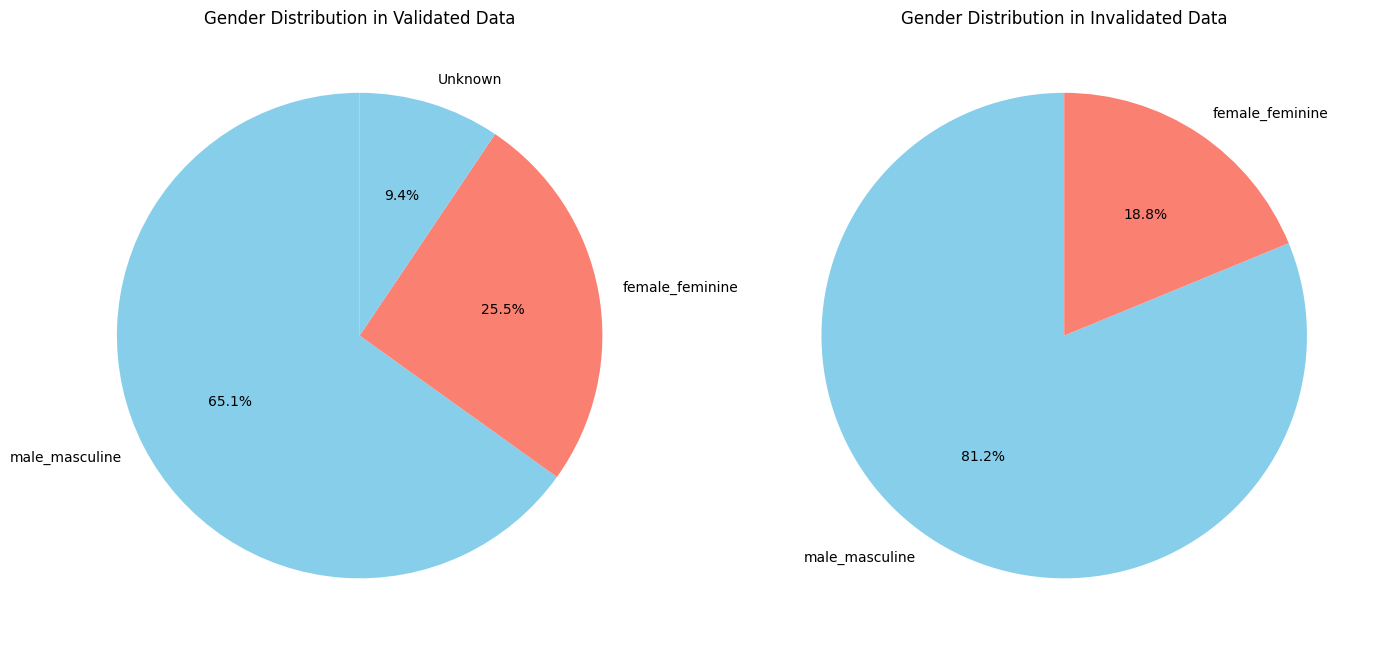

In [33]:
validated_gender_counts = validated_df_clean['gender'].value_counts()
invalidated_gender_counts = invalidated_df_clean['gender'].value_counts()
plt.figure(figsize=(14, 7))

#Pie chart for validated data
plt.subplot(1, 2, 1)
validated_gender_counts.plot(kind='pie', autopct='%1.1f%%', colors=['skyblue', 'salmon'], startangle=90)
plt.title('Gender Distribution in Validated Data')
plt.ylabel('')  # Hide the y-label for pie chart

#Pie chart for invalidated data
plt.subplot(1, 2, 2)
invalidated_gender_counts.plot(kind='pie', autopct='%1.1f%%', colors=['skyblue', 'salmon'], startangle=90)
plt.title('Gender Distribution in Invalidated Data')
plt.ylabel('')  # Hide the y-label for pie chart

plt.tight_layout()
plt.show()

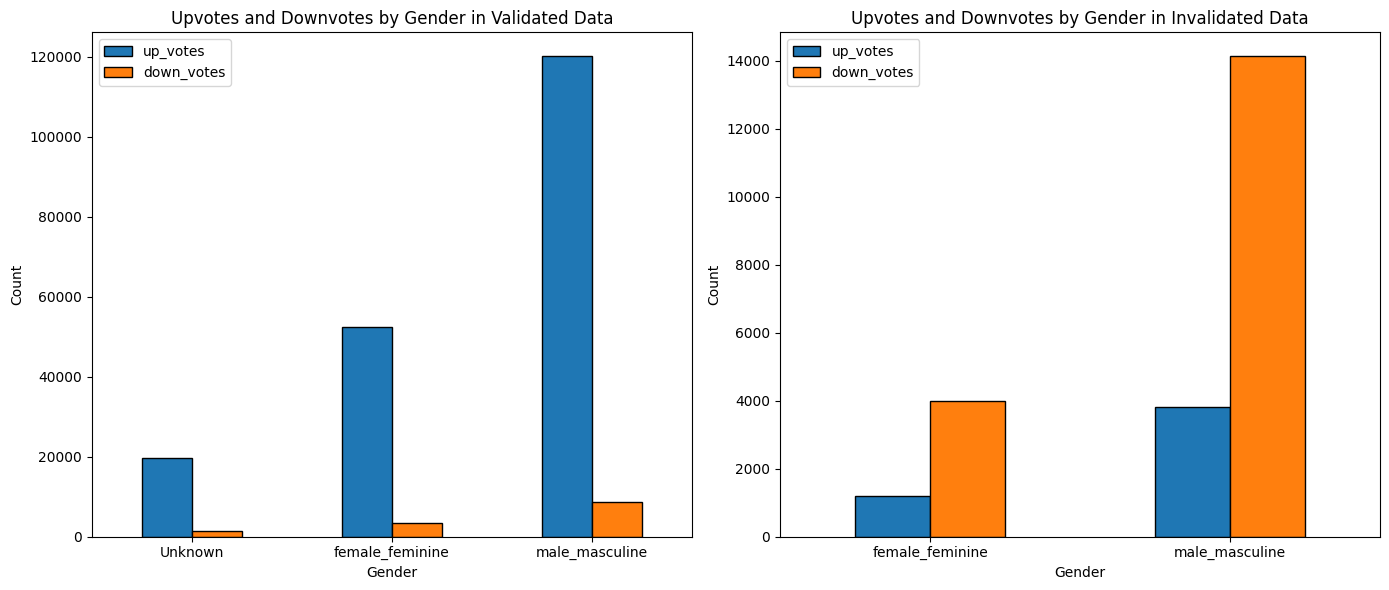

In [34]:
validated_gender_votes = validated_df_clean.groupby('gender').agg({'up_votes': 'sum', 'down_votes': 'sum'})

# Aggregate upvotes and downvotes by gender for invalidated data
invalidated_gender_votes = invalidated_df_clean.groupby('gender').agg({'up_votes': 'sum', 'down_votes': 'sum'})

plt.figure(figsize=(14, 6))

# Histogram for validated data
plt.subplot(1, 2, 1)
validated_gender_votes.plot(kind='bar', edgecolor='black', ax=plt.gca())
plt.title('Upvotes and Downvotes by Gender in Validated Data')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.xticks(rotation=0)

# Histogram for invalidated data
plt.subplot(1, 2, 2)
invalidated_gender_votes.plot(kind='bar', edgecolor='black', ax=plt.gca())
plt.title('Upvotes and Downvotes by Gender in Invalidated Data')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


In [35]:
print(reported_df.columns)
print(invalidated_df_clean.columns)


Index(['sentence_id', 'sentence', 'locale', 'reason'], dtype='object')
Index(['client_id', 'path', 'sentence_id', 'sentence', 'up_votes',
       'down_votes', 'age', 'gender', 'accents', 'locale'],
      dtype='object')


In [36]:
merged_df = pd.merge(reported_df, invalidated_df_clean, on='sentence_id', how='inner')  # or 'left', 'right', or 'outer'

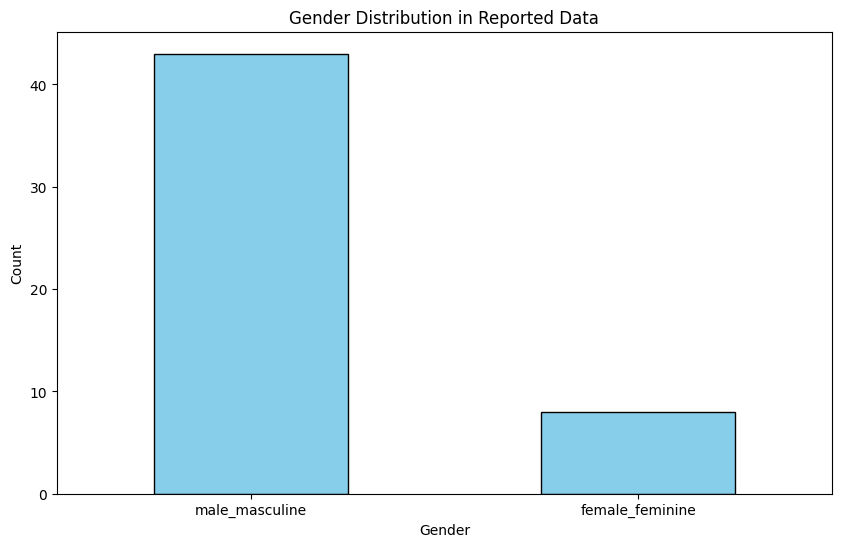

In [37]:
gender_counts = merged_df['gender'].value_counts()
#Plotting a bar chart
plt.figure(figsize=(10, 6))
gender_counts.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Gender Distribution in Reported Data')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

<ipython-input-38-5844a0c0e0ad>:34: UserWarning: Glyph 1729 (\N{ARABIC LETTER HEH GOAL}) missing from current font.
  plt.tight_layout()
<ipython-input-38-5844a0c0e0ad>:34: UserWarning: Matplotlib currently does not support Arabic natively.
  plt.tight_layout()
<ipython-input-38-5844a0c0e0ad>:34: UserWarning: Glyph 1746 (\N{ARABIC LETTER YEH BARREE}) missing from current font.
  plt.tight_layout()
<ipython-input-38-5844a0c0e0ad>:34: UserWarning: Glyph 1748 (\N{ARABIC FULL STOP}) missing from current font.
  plt.tight_layout()
<ipython-input-38-5844a0c0e0ad>:34: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()
/usr/local/lib/python3.10/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 1729 (\N{ARABIC LETTER HEH GOAL}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.10/dist-packages/IPython/core/pylabtools.py:151: UserWarning: M

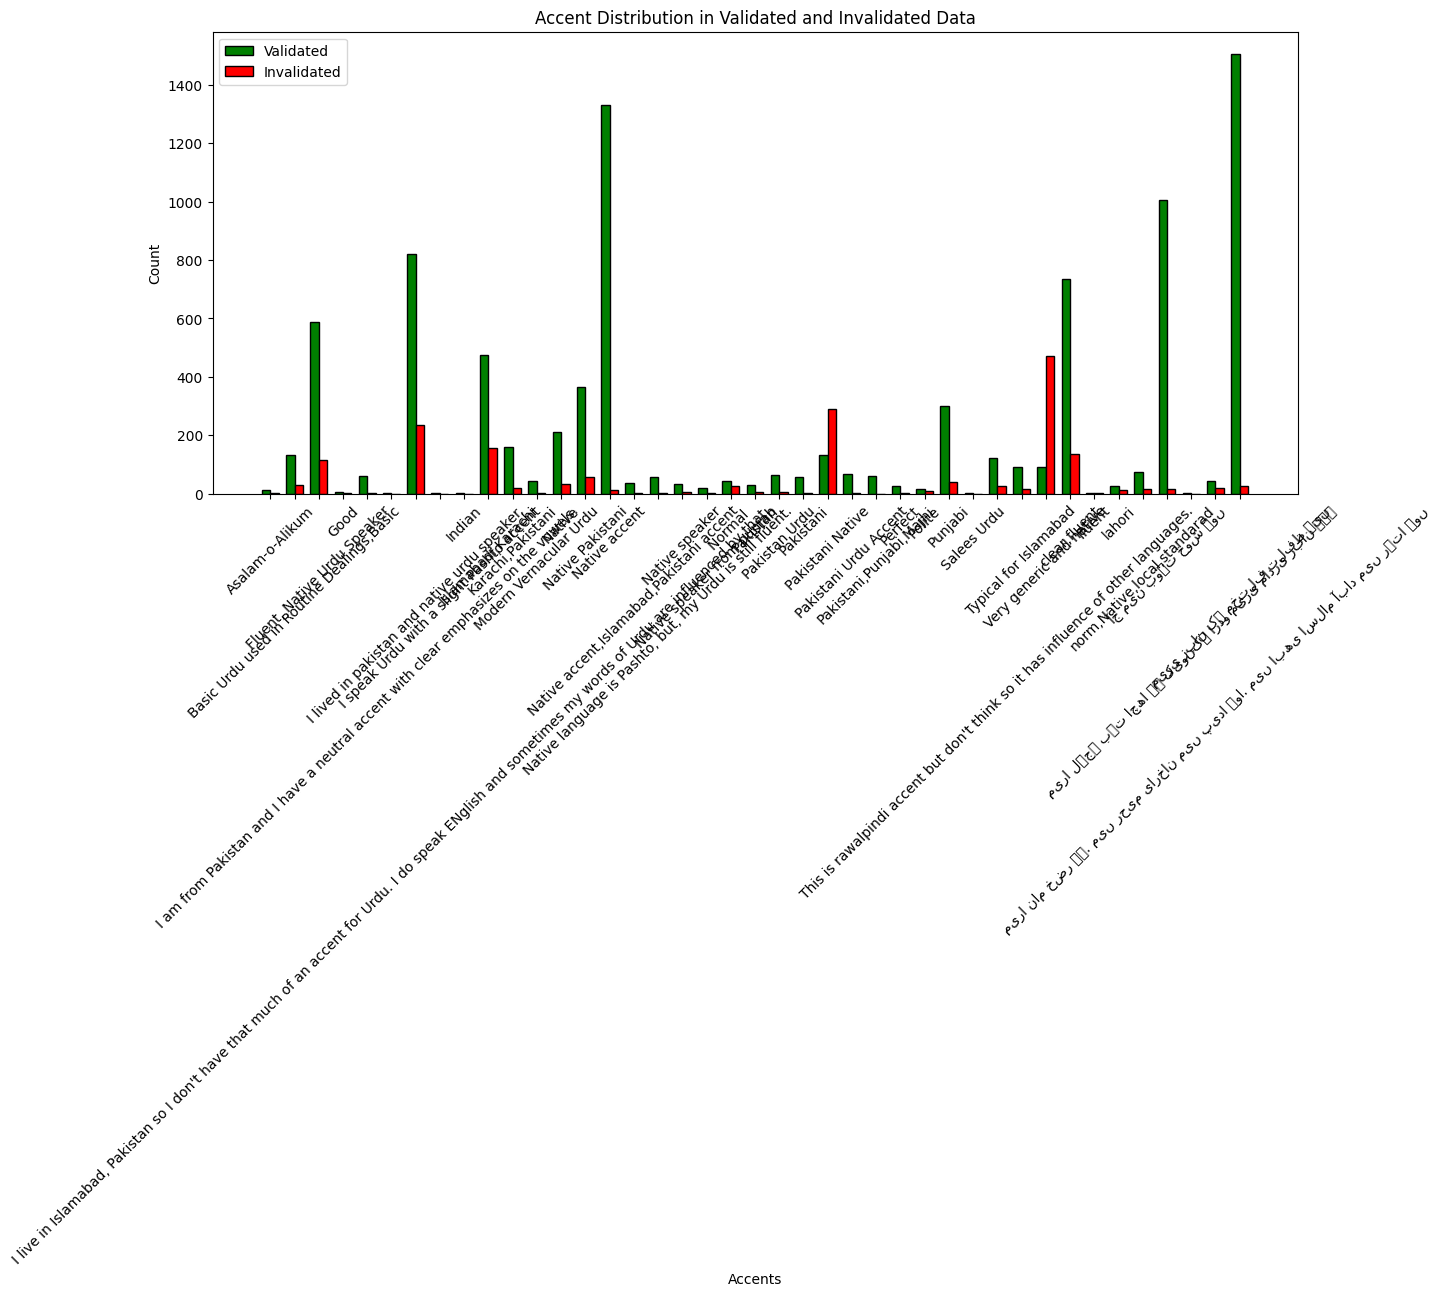

In [38]:
validated_accent_counts = validated_df_clean['accents'].value_counts()
invalidated_accent_counts = invalidated_df_clean['accents'].value_counts()

#Combine both counts into a single DataFrame to ensure we align by common accents
combined_accent_counts = pd.DataFrame({
    'Validated': validated_accent_counts,
    'Invalidated': invalidated_accent_counts
}).fillna(0)
plt.figure(figsize=(14, 6))
bar_width = 0.35
index = np.arange(len(combined_accent_counts))

#Bar plot for validated data
plt.bar(index, combined_accent_counts['Validated'], bar_width, label='Validated', color='green', edgecolor='black')

#Bar plot for invalidated data, slightly overlaped
plt.bar(index + bar_width, combined_accent_counts['Invalidated'], bar_width, label='Invalidated', color='red', edgecolor='black')

plt.title('Accent Distribution in Validated and Invalidated Data')
plt.xlabel('Accents')
plt.ylabel('Count')
plt.xticks(index + bar_width / 2, combined_accent_counts.index, rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


AUDIO DATA EDA

In [39]:
print("\nClip Duration DataFrame Descriptive Statistics:")
print(clip_duration_df.describe())


Clip Duration DataFrame Descriptive Statistics:
        duration[ms]
count  196558.000000
mean     4246.105658
std      3371.821598
min       216.000000
25%      2916.000000
50%      3888.000000
75%      5040.000000
max    278460.000000


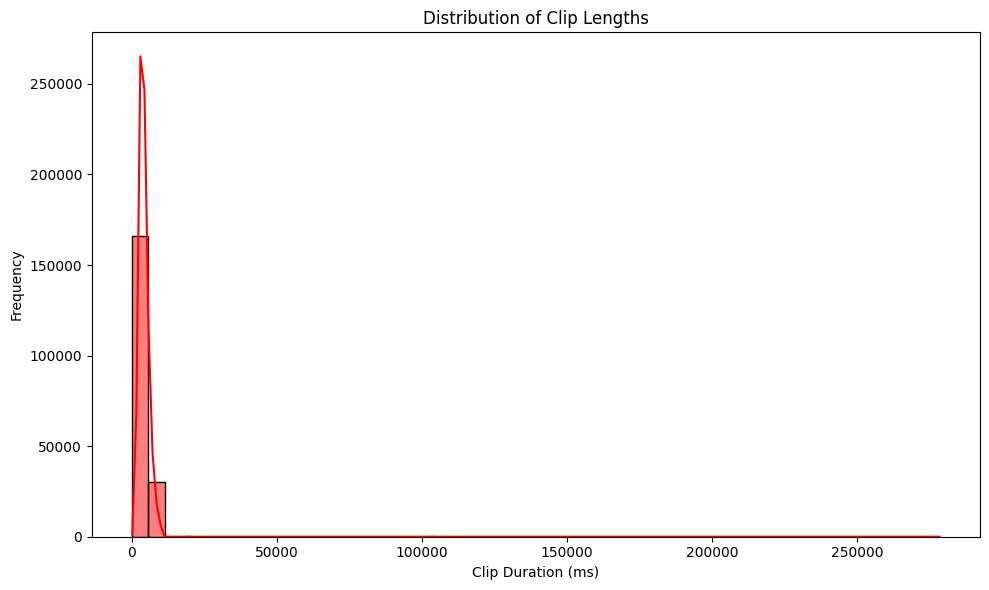

In [40]:
#Distribution of clip lengths
plt.figure(figsize=(10, 6))
sns.histplot(clip_duration_df['duration[ms]'], bins=50, kde=True, color='red', edgecolor='black')

plt.title('Distribution of Clip Lengths')
plt.xlabel('Clip Duration (ms)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [41]:
total_files = clip_duration_df.shape[0]
print(f"Total number of audio files: {total_files}")

Total number of audio files: 196558


Added 3906 audio files on collab and now for some time i'll be using these audio files

In [50]:
audio_folder = '/content/sample_data/Audios'
audio_file_count = 0
for file_name in os.listdir(audio_folder):
    if file_name.endswith('.mp3'):  # Assuming your audio files are in .wav format
        audio_file_count += 1

print(f'Total number of audio files in the folder: {audio_file_count}')

Total number of audio files in the folder: 3906


Converting these mp3 files into wav format

In [51]:
audio_folder = '/content/sample_data/Audios'
wav_folder = '/content/sample_data/Converted_wav_audios'
if not os.path.exists(wav_folder):
    os.makedirs(wav_folder)

for file_name in os.listdir(audio_folder):
    if file_name.endswith('.mp3'):
        mp3_path = os.path.join(audio_folder, file_name)

        #Convert MP3 to WAV
        audio = AudioSegment.from_mp3(mp3_path)
        wav_file_name = file_name.replace('.mp3', '.wav')
        wav_path = os.path.join(wav_folder, wav_file_name)
        audio.export(wav_path, format="wav")

        #Load the converted WAV file using librosa
        y, sr = librosa.load(wav_path, sr=None)

print('All files processed.')

All files processed.


Feature extraction on those wav files and visualising them



In [54]:
audio_features = []

for file_name in os.listdir(wav_folder):
    if file_name.endswith('.wav'):
        wav_path = os.path.join(wav_folder, file_name)

        y, sr = librosa.load(wav_path, sr=None)

        #Feature Extraction
        duration = librosa.get_duration(y=y, sr=sr)  # Duration of the audio
        tempo, _ = librosa.beat.beat_track(y=y, sr=sr)  # Tempo (BPM)
        zcr = librosa.feature.zero_crossing_rate(y).mean()  # Zero-crossing rate
        spectral_centroid = librosa.feature.spectral_centroid(y=y, sr=sr).mean()  # Spectral centroid
        rms = librosa.feature.rms(y=y).mean()  # Root Mean Square (Energy)

        #Silence intervals
        silent_intervals = librosa.effects.split(y, top_db=20)
        num_silent_segments = len(silent_intervals)
        total_silence = sum([end - start for start, end in silent_intervals]) / sr

        audio_features.append({
            'File Name': file_name,
            'Duration (seconds)': duration,
            'Tempo (BPM)': tempo,
            'Zero Crossing Rate': zcr,
            'Spectral Centroid': spectral_centroid,
            'RMS (Energy)': rms,
            'Number of Silent Segments': num_silent_segments,
            'Total Silence Duration (seconds)': total_silence
        })

wav_audios = pd.DataFrame(audio_features)
print(wav_audios)

                         File Name  Duration (seconds)           Tempo (BPM)  \
0     common_voice_ur_31933911.wav               3.420   [81.52173913043478]   
1     common_voice_ur_31836836.wav               1.980  [110.29411764705883]   
2     common_voice_ur_31870536.wav               2.808   [89.28571428571429]   
3     common_voice_ur_32043932.wav               2.664  [138.88888888888889]   
4     common_voice_ur_31919799.wav               3.096              [156.25]   
...                            ...                 ...                   ...   
3901  common_voice_ur_31968227.wav               2.196  [178.57142857142858]   
3902  common_voice_ur_31938139.wav               1.800               [187.5]   
3903  common_voice_ur_31987047.wav               2.340  [133.92857142857142]   
3904  common_voice_ur_38442934.wav               3.816               [150.0]   
3905  common_voice_ur_31857047.wav               1.908  [138.88888888888889]   

      Zero Crossing Rate  Spectral Cent

In [80]:
wav_audios.to_csv('wav_audio_features.csv', index=False)
print(wav_audios.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3906 entries, 0 to 3905
Data columns (total 8 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   File Name                         3906 non-null   object 
 1   Duration (seconds)                3906 non-null   float64
 2   Tempo (BPM)                       0 non-null      float64
 3   Zero Crossing Rate                3906 non-null   float64
 4   Spectral Centroid                 3906 non-null   float64
 5   RMS (Energy)                      3906 non-null   float32
 6   Number of Silent Segments         3906 non-null   int64  
 7   Total Silence Duration (seconds)  3906 non-null   float64
dtypes: float32(1), float64(5), int64(1), object(1)
memory usage: 229.0+ KB
None


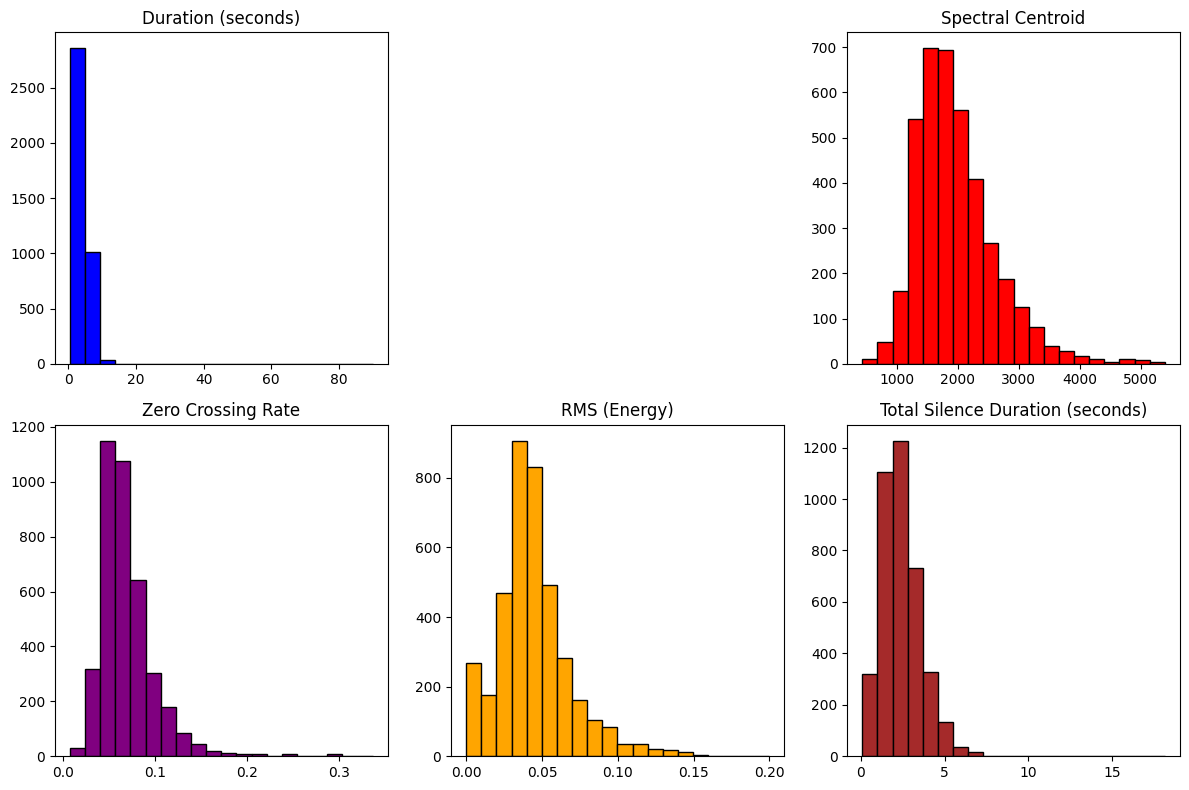

In [77]:
#Histograms of the extracted features
plt.figure(figsize=(12, 8))
plt.subplot(2, 3, 1)
plt.hist(wav_audios['Duration (seconds)'], bins=20, color='blue', edgecolor='black')
plt.title('Duration (seconds)')

plt.subplot(2, 3, 2)
plt.hist(wav_audios['Tempo (BPM)'], bins=20, color='green', edgecolor='black')
plt.title('Tempo (BPM)')

plt.subplot(2, 3, 3)
plt.hist(wav_audios['Spectral Centroid'], bins=20, color='red', edgecolor='black')
plt.title('Spectral Centroid')

plt.subplot(2, 3, 4)
plt.hist(wav_audios['Zero Crossing Rate'], bins=20, color='purple', edgecolor='black')
plt.title('Zero Crossing Rate')

plt.subplot(2, 3, 5)
plt.hist(wav_audios['RMS (Energy)'], bins=20, color='orange', edgecolor='black')
plt.title('RMS (Energy)')

plt.subplot(2, 3, 6)
plt.hist(wav_audios['Total Silence Duration (seconds)'], bins=20, color='brown', edgecolor='black')
plt.title('Total Silence Duration (seconds)')

plt.tight_layout()
plt.show()

Visualisation of silence duration throughout the audio sample

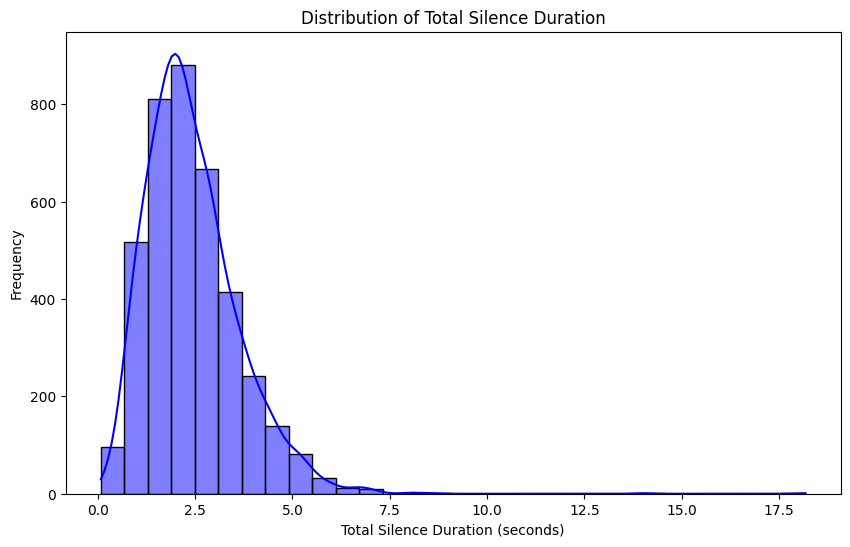

In [63]:
plt.figure(figsize=(10, 6))
sns.histplot(wav_audios['Total Silence Duration (seconds)'], bins=30, kde=True, color='blue')
plt.title('Distribution of Total Silence Duration')
plt.xlabel('Total Silence Duration (seconds)')
plt.ylabel('Frequency')
plt.show()

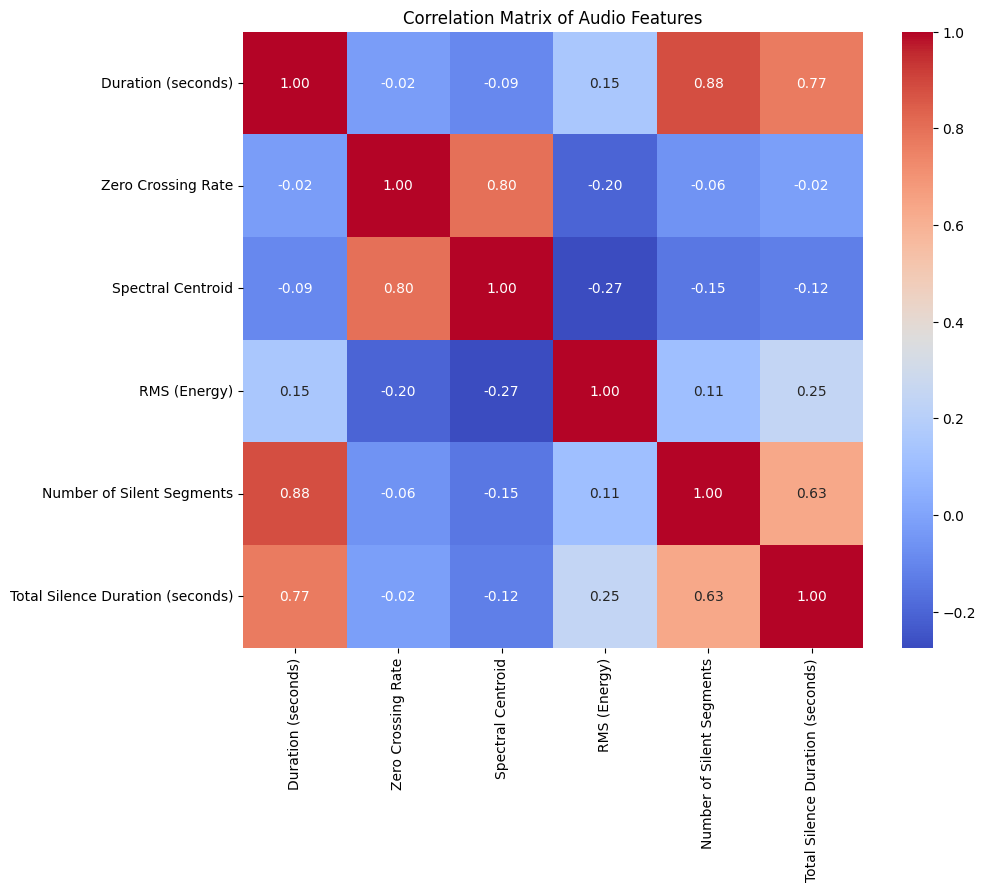

In [67]:
numeric_columns = wav_audios.select_dtypes(include=['float64', 'float32', 'int64']).columns
corr_matrix = wav_audios[numeric_columns].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Audio Features')
plt.show()

In vscode i had issue with pydub lib so i created a sample of 5000 audios and did feature engineering and did some further EDA on it as shown bellow:

In [ ]:
audio_folder = r"D:\University\Semester 7\NLP\Assignment 2 (ETL)\ur\clips"

In [ ]:
import os
import random
import shutil

# Define the folder containing audio files and the destination folder
audio_folder = r"D:\University\Semester 7\NLP\Assignment 2 (ETL)\ur\clips"
destination_folder = r"D:\University\Semester 7\NLP\Assignment 2 (ETL)\ur\Audiosample"

# Create the destination folder if it does not exist
os.makedirs(destination_folder, exist_ok=True)

# List all .mp3 files in the folder
all_files = [f for f in os.listdir(audio_folder) if f.endswith(".mp3")]

# Ensure there are enough files to sample
if len(all_files) < 5000:
    print("Error: Not enough files to sample.")
else:
    # Randomly sample 5000 files
    sampled_files = random.sample(all_files, 5000)

    # Copy sampled files to the destination folder
    for filename in sampled_files:
        src_path = os.path.join(audio_folder, filename)
        dst_path = os.path.join(destination_folder, filename)
        shutil.copy(src_path, dst_path)

    print(f"Copied {len(sampled_files)} files to '{destination_folder}'.")


In [ ]:

audio_sample_folder = r"D:\University\Semester 7\NLP\Assignment 2 (ETL)\ur\Audiosample"
import librosa
import pandas as pd
import numpy as np
import os

# Path to the folder containing audio samples
audio_folder = r"D:\University\Semester 7\NLP\Assignment 2 (ETL)\ur\Audiosample"

# List all audio files in the folder
audio_files = [f for f in os.listdir(audio_folder) if f.endswith('.mp3')]

# Initialize a list to store feature data
feature_list = []

# Define a function to extract features from an audio file
def extract_features(file_path):
    # Load the audio file
    y, sr = librosa.load(file_path, sr=None)

    # Extract features
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    chroma = librosa.feature.chroma_stft(y=y, sr=sr)
    spectral_contrast = librosa.feature.spectral_contrast(y=y, sr=sr)
    tonnetz = librosa.feature.tonnetz(y=y, sr=sr)

    # Aggregate features
    features = {
        'filename': os.path.basename(file_path),
        'mfcc_mean': np.mean(mfccs, axis=1).tolist(),
        'chroma_mean': np.mean(chroma, axis=1).tolist(),
        'spectral_contrast_mean': np.mean(spectral_contrast, axis=1).tolist(),
        'tonnetz_mean': np.mean(tonnetz, axis=1).tolist()
    }

    return features

# Process each audio file and extract features
for audio_file in audio_files:
    file_path = os.path.join(audio_folder, audio_file)
    features = extract_features(file_path)
    feature_list.append(features)

# Convert feature list to DataFrame
features_df = pd.DataFrame(feature_list)

# Save the features DataFrame to a CSV file
features_df.to_csv(r'D:\University\Semester 7\NLP\Assignment 2 (ETL)\ur\audio_features.csv', index=False)

print("Feature extraction complete. Features saved to 'audio_features.csv'.")



In [ ]:
features_df = pd.read_csv(r'D:\University\Semester 7\NLP\Assignment 2 (ETL)\ur\audio_features.csv')
print(features_df.head())
print(features_df.columns)
print(features_df.describe())


Now using this Audio_features.csv i'll do some EDA on the sample data of 5000 audio files

In [85]:
df = pd.read_csv('/content/sample_data/audio_features.csv')
#Convert string representations of lists to actual lists
df['mfcc_mean'] = df['mfcc_mean'].apply(lambda x: ast.literal_eval(x))
df['chroma_mean'] = df['chroma_mean'].apply(lambda x: ast.literal_eval(x))
df['spectral_contrast_mean'] = df['spectral_contrast_mean'].apply(lambda x: ast.literal_eval(x))
df['tonnetz_mean'] = df['tonnetz_mean'].apply(lambda x: ast.literal_eval(x))

In [86]:
#calculate mean of list elements
def mean_of_list(lst):
    return np.mean(lst) if len(lst) > 0 else np.nan

#Calculate means
df['mfcc_mean'] = df['mfcc_mean'].apply(mean_of_list)
df['chroma_mean'] = df['chroma_mean'].apply(mean_of_list)
df['spectral_contrast_mean'] = df['spectral_contrast_mean'].apply(mean_of_list)
df['tonnetz_mean'] = df['tonnetz_mean'].apply(mean_of_list)

print(df[['mfcc_mean', 'chroma_mean', 'spectral_contrast_mean', 'tonnetz_mean']].describe())


         mfcc_mean  chroma_mean  spectral_contrast_mean  tonnetz_mean
count  5000.000000  5000.000000             5000.000000   5000.000000
mean    -24.201306     0.394446               22.831460      0.002799
std       7.600735     0.069266                1.594142      0.013757
min     -78.425302     0.170792                8.965181     -0.066376
25%     -28.095571     0.351052               22.016120     -0.005352
50%     -22.925826     0.388077               22.916874      0.001865
75%     -19.196063     0.429129               23.799766      0.009503
max      -0.834154     0.723921               28.178571      0.141716


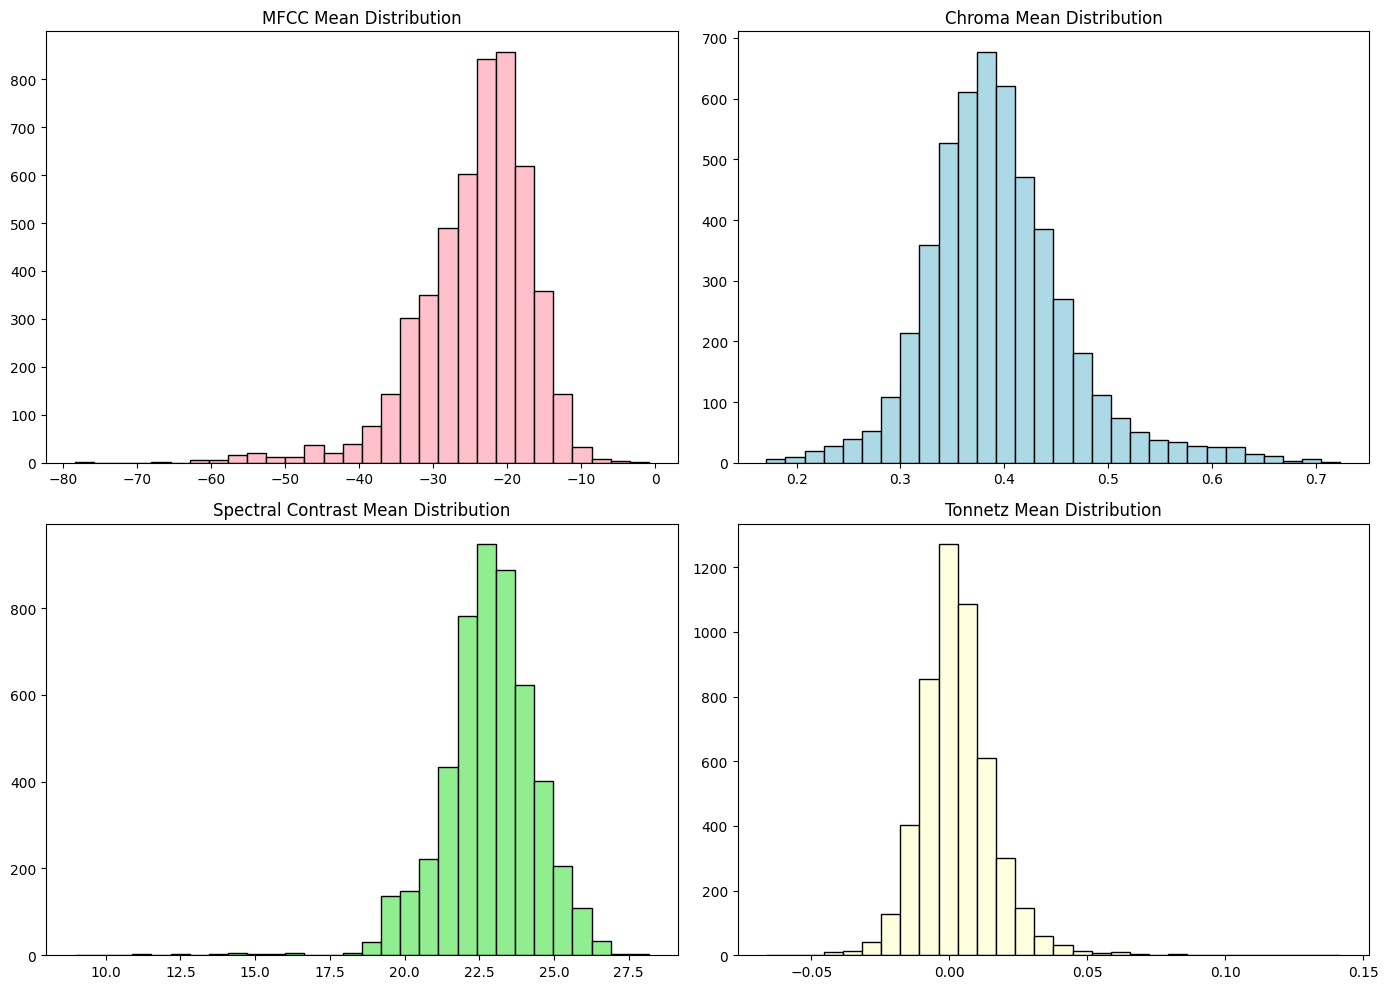

In [92]:
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

axs[0, 0].hist(df['mfcc_mean'].dropna(), bins=30, color='pink', edgecolor='black')
axs[0, 0].set_title('MFCC Mean Distribution')

axs[0, 1].hist(df['chroma_mean'].dropna(), bins=30, color='lightblue', edgecolor='black')
axs[0, 1].set_title('Chroma Mean Distribution')

axs[1, 0].hist(df['spectral_contrast_mean'].dropna(), bins=30, color='lightgreen', edgecolor='black')
axs[1, 0].set_title('Spectral Contrast Mean Distribution')

axs[1, 1].hist(df['tonnetz_mean'].dropna(), bins=30, color='lightyellow', edgecolor='black')
axs[1, 1].set_title('Tonnetz Mean Distribution')

plt.tight_layout()
plt.show()


Checking Speaker diversity using PCA

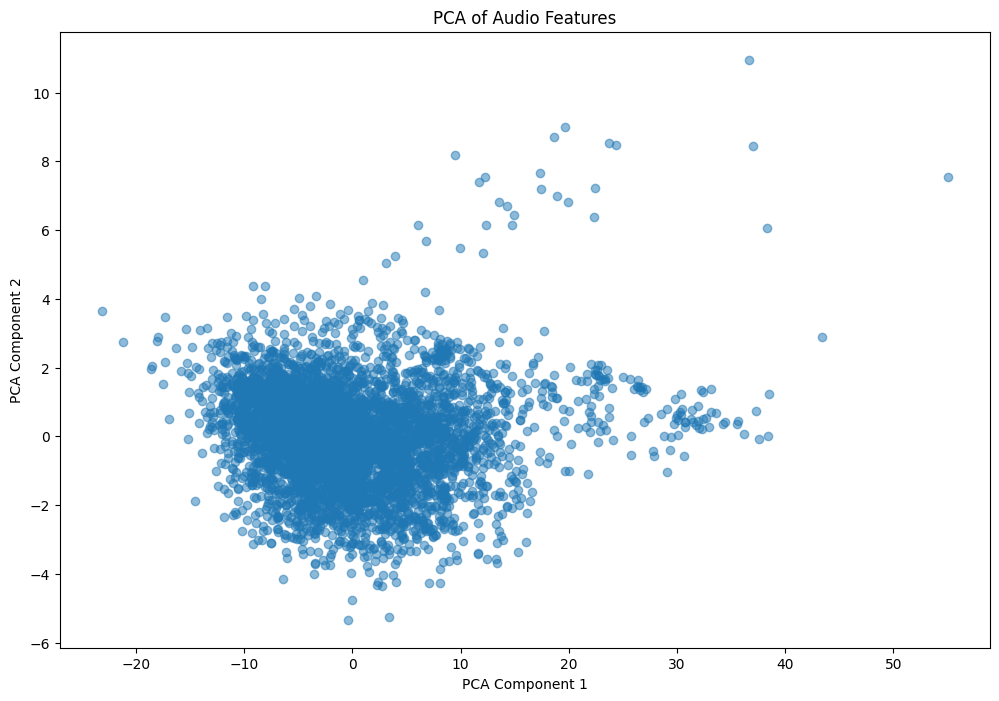

In [96]:
mfcc_df = pd.DataFrame(df['mfcc_mean'].tolist())
chroma_df = pd.DataFrame(df['chroma_mean'].tolist())
spectral_contrast_df = pd.DataFrame(df['spectral_contrast_mean'].tolist())
tonnetz_df = pd.DataFrame(df['tonnetz_mean'].tolist())

features_df = pd.concat([mfcc_df, chroma_df, spectral_contrast_df, tonnetz_df], axis=1)

#Perform PCA to reduce the features to 2D
pca = PCA(n_components=2)
pca_result = pca.fit_transform(features_df)

pca_df = pd.DataFrame(data=pca_result, columns=['PCA1', 'PCA2'])
pca_df['filename'] = df['filename']

plt.figure(figsize=(12, 8))
plt.scatter(pca_df['PCA1'], pca_df['PCA2'], alpha=0.5)
plt.title('PCA of Audio Features')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()

On a single audio file EDA

In [57]:
#Convert MP3 to WAV
audio = AudioSegment.from_mp3("/content/sample_data/Audios/common_voice_ur_26574926.mp3")
audio.export("path_to_audio.wav", format="wav")
# Load the WAV file
y, sr = librosa.load("path_to_audio.wav", sr=None)

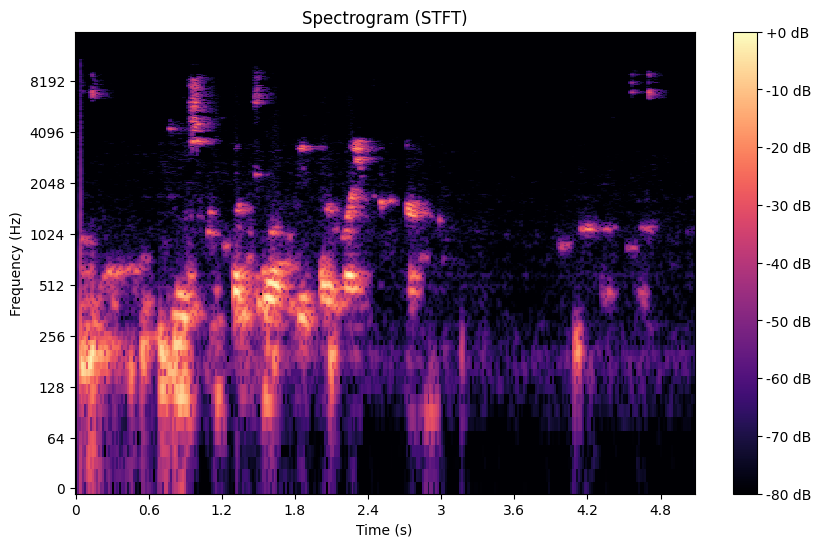

In [58]:
audio_path = '/content/sample_data/Converted_wav_audios/common_voice_ur_26574926.wav'
y, sr = librosa.load(audio_path, sr=None)

# Compute the Short-Time Fourier Transform (STFT) to get the spectrogram
D = np.abs(librosa.stft(y))  # STFT of the audio

# Convert the amplitude to decibels (dB) for a better visualization
S_db = librosa.amplitude_to_db(D, ref=np.max)

# Plot the spectrogram
plt.figure(figsize=(10, 6))
librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='log', cmap='magma')

# Add titles and labels
plt.colorbar(format='%+2.0f dB')
plt.title('Spectrogram (STFT)')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')

# Display the plot
plt.show()

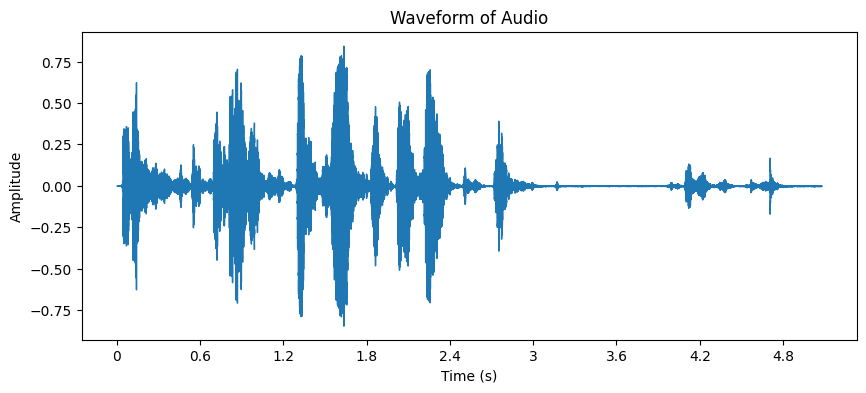

In [59]:
plt.figure(figsize=(10, 4))
librosa.display.waveshow(y, sr=sr)
plt.title('Waveform of Audio')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.show()

MFCCs shape: (20, 318)


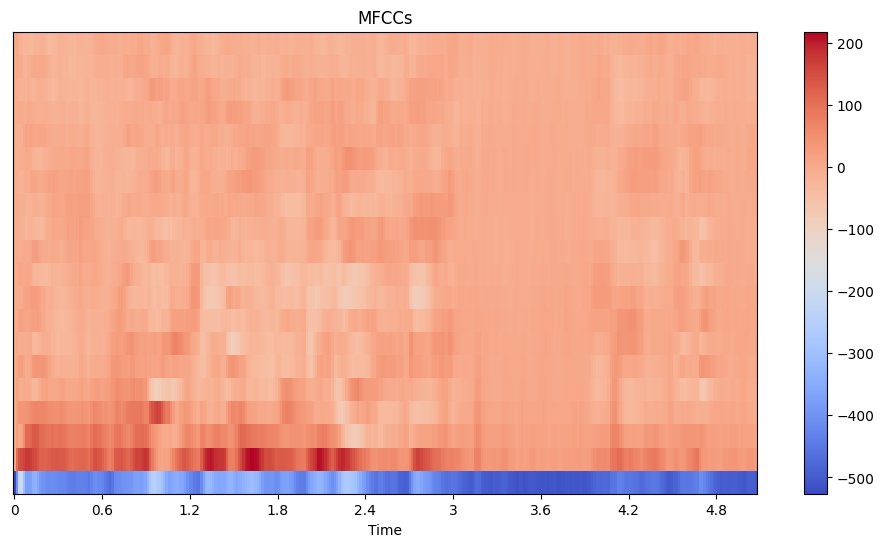

In [60]:
mfccs = librosa.feature.mfcc(y=y, sr=sr)
print(f"MFCCs shape: {mfccs.shape}")

plt.figure(figsize=(12, 6))
librosa.display.specshow(mfccs, sr=sr, x_axis='time')
plt.colorbar()
plt.title('MFCCs')
plt.show()